# Model Calibration and Uncertainty: can you trust a "90% sure"?

**The question:** a classifier does not only say "cat"; it says "cat, 97% sure". That number is used everywhere: to decide whether to trust the answer, to send doubtful cases to a human, to price a risk. But **is it honest?** If a model says "90% sure" on a thousand images, is it right on about 900 of them? Modern neural networks are famously **over-confident**: they say 99% when they are right 90% of the time. *How over-confident is a typical CIFAR-10 network, and how do we measure it (reliability diagrams, the expected calibration error)? Does one number, a "temperature", fix it? How do other remedies compare: better training, label smoothing, ensembles? Does the confidence help to find mistakes and strangers? And does the fix survive when the images change?* We train 11 networks, so everything comes with seeds and honest tests.

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. Hypotheses and why we chose each test
4. Audit: three image sets and a spare validation set
5. Networks and training recipes
6. The measuring tools
7. H1: how over-confident is the network?
8. H2: does temperature scaling fix it?
9. H3: what do the other remedies do?
10. H4: does uncertainty find mistakes and strangers?
11. H5: does calibration survive a change in the data?
12. Takeaways
13. Limitations

**Run it:** `uv run jupyter lab DL/model-calibration-uncertainty/model_calibration_uncertainty.ipynb`, or *Run All* in any Jupyter. The image sets (about 400 MB) download themselves on the first run. It uses a GPU if present and takes about 12 minutes on one.

## 1. 💡 The simple analogy

Think of a **weather forecaster**.

- A **well-calibrated** forecaster who says "70% chance of rain" on 100 different days sees rain on about 70 of them. The number *means* something.
- An **over-confident** forecaster says "99% rain" and is right on only 90 days of 100. Every forecast sounds certain, which is exactly why you cannot tell the shaky ones from the solid ones.
- A **reliability diagram** is the forecaster's report card: for every announced percentage (10%, 20%, ... 100%) it shows how often it really rained.
- **Temperature scaling** is like telling the forecaster to **turn the volume down**: take every announced number and soften it by the same amount, until the report card is honest. It does not change *which* day he thinks is wettest, only how loudly he says it.
- An **ensemble** is a panel of forecasters: when they disagree, you hear the doubt.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the seed, the number of epochs, how many networks of each kind we train (5 plain, 3 with augmentation, 3 with label smoothing), the number of confidence bins (15) and the noise levels keeps the notebook reproducible and avoids "magic numbers". The seed fixes every network, so reruns give the same numbers.

In [1]:
# ruff: noqa: E402 (the settings below must come before the imports that read them)
import os
import warnings

os.environ["HF_HUB_DISABLE_PROGRESS_BARS"] = "1"
warnings.filterwarnings("ignore", message="IProgress not found")
from pathlib import Path

import datasets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
import torch.nn.functional as F
from datasets import load_dataset
from huggingface_hub.utils import logging as hub_logging
from scipy import stats
from sklearn.metrics import roc_auc_score
from statsmodels.stats.contingency_tables import mcnemar
from torch import nn

hub_logging.set_verbosity_error()

DATA_DIR = Path("data")
OUT_DIR = Path("outputs")
SEED = 365
EPOCHS = 20
BATCH_SIZE = 256
N_SEEDS = {"plain": 5, "augmented": 3, "label smoothing": 3}
LABEL_SMOOTHING = 0.1
N_BINS = 15  # confidence bins of the reliability diagram and the ECE
NOISE_LEVELS = [0.0, 0.05, 0.1, 0.15, 0.2, 0.3]
N_BOOTSTRAP = 1_000
N_VALIDATION = 5_000
N_OOD = 10_000
MEAN = torch.tensor([0.4914, 0.4822, 0.4465]).view(1, 3, 1, 1)
STD = torch.tensor([0.2470, 0.2435, 0.2616]).view(1, 3, 1, 1)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
TEAL, ORANGE, NAVY, GREY, PURPLE = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2", "#7b5ea7"

sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)
DATA_DIR.mkdir(exist_ok=True)
rng = np.random.default_rng(SEED)
torch.backends.cudnn.deterministic = True  # same seed, same result, even on the GPU


def fmt_p(p: float) -> str:
    """Formats a p-value, showing values below floating-point precision honestly.

    Args:
        p: The p-value.

    Returns:
        A short string such as ``3.2e-08`` or ``< 1e-300``.
    """
    return "< 1e-300" if float(p) < 1e-300 else f"{float(p):.1e}"

## 3. Hypotheses and why we chose each test

| # | Question | H₀ (nothing interesting) | Hₐ | Test |
|---|---|---|---|---|
| H1 | Are the networks calibrated, or does their confidence exceed their accuracy? | Average confidence equals accuracy | Confidence exceeds accuracy | Expected calibration error with a bootstrap interval; one-sample t-test of (confidence - accuracy) over 5 networks |
| H2 | Does temperature scaling (one number fitted on spare images) reduce the calibration error without changing a single prediction? | No change | ECE and NLL fall; predictions identical | Paired t-tests over 5 networks; count of changed predictions |
| H3 | How do augmentation, label smoothing and ensembles compare with temperature scaling? | Same ECE and NLL | Differ | ECE, NLL, Brier score and accuracy of each remedy; McNemar test and bootstrap intervals for the ensemble |
| H4 | Is the confidence useful: does it flag wrong answers and images of other things? | No better than a coin | Better than chance | AUROC for "right vs wrong" and "CIFAR-10 vs CIFAR-100 / SVHN"; accuracy when answering only the most confident images |
| H5 | Does calibration fitted on clean images survive noisy images? | Same ECE under noise | Much worse | ECE of the plain, temperature-scaled and ensemble models at six noise levels |

*Why these tests?* The **expected calibration error (ECE)** compares confidence with accuracy bin by bin; it has no standard error, so we **bootstrap** the test images. The **negative log-likelihood (NLL)** and the **Brier score** are proper scoring rules: they reward honest probabilities (a lower value is better). The 5 networks differ only by their random seed, so we compare methods with **paired** tests over seeds, which respect that the same seed gives the same starting point.

## 4. Audit: three image sets and a spare validation set

*What:* **CIFAR-10** (ten everyday object classes, 32 x 32 pixel colour photographs) is split into **45,000 training**, **5,000 validation** and **10,000 test** images. The validation images are *never* used to train the networks: they are the **spare images** used only to fit the calibration (so the test set stays untouched: no leakage). Two sets of unfamiliar images test the uncertainty: **CIFAR-100** (other everyday objects that are none of the ten classes) and **SVHN** (photographs of street numbers). Gaussian noise is added to the test images to simulate a change in the data. *Why:* calibration is meaningful only on data the model did not train on, and the validation and test roles must be kept apart.

> **Not in this project's legacy:** there is no old code to replace (a new project).

In [2]:
def load(name: str, split: str, config: str | None = None) -> tuple[torch.Tensor, np.ndarray]:
    """Loads an image set from the Hugging Face hub as float tensors in [0, 1], channels first.

    Args:
        name: Dataset id on the hub.
        split: ``train`` or ``test``.
        config: Optional dataset configuration (SVHN has several).

    Returns:
        The images (N, 3, 32, 32) and their labels.
    """
    ds = load_dataset(name, config, split=split, cache_dir=str(DATA_DIR / "hf"))
    image_col = "img" if "img" in ds.column_names else "image"
    label_col = "label" if "label" in ds.column_names else "fine_label"
    images = np.stack([np.asarray(im.convert("RGB")) for im in ds[image_col]])
    return torch.from_numpy(images).permute(0, 3, 1, 2).float() / 255, np.array(ds[label_col])


datasets.disable_progress_bars()
train_all_x, train_all_y = load("uoft-cs/cifar10", "train")
test_x_raw, test_y = load("uoft-cs/cifar10", "test")
cifar100_x, _ = load("uoft-cs/cifar100", "test")
svhn_x, _ = load("ufldl-stanford/svhn", "test", "cropped_digits")
svhn_x = svhn_x[torch.from_numpy(rng.permutation(len(svhn_x))[:N_OOD])]

order = rng.permutation(len(train_all_x))
val_idx, train_idx = order[:N_VALIDATION], order[N_VALIDATION:]
train_x_raw, train_y_split = train_all_x[train_idx], train_all_y[train_idx]
val_x_raw, val_y = train_all_x[val_idx], train_all_y[val_idx]
print(
    f"CIFAR-10: {len(train_x_raw):,} training, {len(val_x_raw):,} validation (used only to "
    f"calibrate) and {len(test_x_raw):,} test images; classes are balanced "
    f"({np.bincount(test_y).min()} to {np.bincount(test_y).max()} per class in the test set)"
)
print(
    f"Out-of-distribution sets: {len(cifar100_x):,} CIFAR-100 test images (other everyday "
    f"objects, none of the ten classes) and {len(svhn_x):,} street-number photographs (SVHN)"
)
print(
    f"Overlap between the validation indices and the training indices: "
    f"{len(set(val_idx) & set(train_idx))}"
)
for name, noise in [("clean", 0.0), ("sigma 0.1", 0.1), ("sigma 0.3", 0.3)]:
    sample = (
        test_x_raw[:1_000]
        + noise * torch.randn(1_000, 3, 32, 32, generator=torch.Generator().manual_seed(0))
    ).clamp(0, 1)
    print(
        f"  noisy test images, {name}: mean pixel {sample.mean():.3f}, "
        f"average distance to the clean image {(sample - test_x_raw[:1_000]).abs().mean():.3f}"
    )

CIFAR-10: 45,000 training, 5,000 validation (used only to calibrate) and 10,000 test images; classes are balanced (1000 to 1000 per class in the test set)
Out-of-distribution sets: 10,000 CIFAR-100 test images (other everyday objects, none of the ten classes) and 10,000 street-number photographs (SVHN)
Overlap between the validation indices and the training indices: 0
  noisy test images, clean: mean pixel 0.478, average distance to the clean image 0.000
  noisy test images, sigma 0.1: mean pixel 0.478, average distance to the clean image 0.077
  noisy test images, sigma 0.3: mean pixel 0.481, average distance to the clean image 0.203


**How to read this:**

- **45,000 training, 5,000 validation and 10,000 test images**; the test set is perfectly balanced (1,000 per class), and **no validation image is among the training images** (overlap 0).
- **Two kinds of strangers:** 10,000 CIFAR-100 images (objects similar in style, none of the ten classes) and 10,000 SVHN street-number photographs (very different).
- **The noise is substantial:** at a standard deviation of 0.1 the average pixel changes by 0.077 (on a 0-to-1 scale), and at 0.3 by 0.203; the mean brightness does not move.

## 5. Networks and training recipes

*What:* one small convolutional network (three blocks of two 3 x 3 convolutions with batch norm, about 290,000 weights) trained with one recipe (AdamW, a one-cycle learning rate, 20 epochs, batches of 256) in three flavours: **plain** (5 seeds; no augmentation, so it fits the training set closely), **augmented** (3 seeds; random flips and shifts), and **label smoothing** (3 seeds; the target "100% cat" is softened to "90% cat", a training trick that is supposed to discourage extreme confidence). Right after training each network we store its **logits** (the raw scores before the softmax) on the validation set, the test set, the two unfamiliar sets and six noisy test sets. *Why:* the plain networks are the over-confident patient; the other flavours are candidate cures.

In [3]:
def augment(batch: torch.Tensor, generator: torch.Generator) -> torch.Tensor:
    """Randomly flips each image left-right and shifts it by up to 4 pixels (on the GPU).

    Args:
        batch: Images of shape (N, 3, 32, 32).
        generator: Random generator on the same device, for reproducibility.

    Returns:
        The augmented batch.
    """
    n = len(batch)
    flip = (torch.randint(0, 2, (n,), device=batch.device, generator=generator) * 2 - 1).float()
    shift = torch.randint(-4, 5, (n, 2), device=batch.device, generator=generator).float() / 16
    theta = torch.zeros(n, 2, 3, device=batch.device)
    theta[:, 0, 0], theta[:, 1, 1] = flip, 1.0
    theta[:, :, 2] = shift
    grid = F.affine_grid(theta, list(batch.shape), align_corners=False)
    return F.grid_sample(batch, grid, padding_mode="reflection", align_corners=False)


def conv_block(c_in: int, c_out: int) -> nn.Sequential:
    """Two 3x3 convolutions with batch norm and ReLU, then 2x2 max pooling."""
    return nn.Sequential(
        nn.Conv2d(c_in, c_out, 3, padding=1, bias=False),
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
        nn.Conv2d(c_out, c_out, 3, padding=1, bias=False),
        nn.BatchNorm2d(c_out),
        nn.ReLU(),
        nn.MaxPool2d(2),
    )


def normalise(images: torch.Tensor) -> torch.Tensor:
    """Standardises raw [0, 1] images with the training means and deviations."""
    return ((images - MEAN) / STD).to(DEVICE)


NOISE_GEN = torch.Generator().manual_seed(SEED)
noisy_sets = {
    s: (test_x_raw + s * torch.randn(test_x_raw.shape, generator=NOISE_GEN)).clamp(0, 1)
    for s in NOISE_LEVELS
    if s > 0
}
EVAL_SETS = {
    "val": val_x_raw,
    "test": test_x_raw,
    "CIFAR-100": cifar100_x,
    "SVHN": svhn_x,
    **{f"noise {s}": x for s, x in noisy_sets.items()},
}


@torch.no_grad()
def logits_of(model: nn.Module, images: torch.Tensor) -> np.ndarray:
    """The raw network outputs (before the softmax) for a set of images."""
    model.eval()
    x = normalise(images)
    return torch.cat([model(x[i : i + 1000]) for i in range(0, len(x), 1000)]).cpu().numpy()


def train_and_evaluate(kind: str, seed: int) -> dict[str, np.ndarray]:
    """Trains one network on CIFAR-10 and returns its logits on every evaluation set.

    All networks share one recipe (AdamW, a one-cycle learning rate, 20 epochs, batches of 256);
    only ``kind`` changes: ``plain`` (no augmentation), ``augmented`` (flips and shifts) or
    ``label smoothing`` (the targets are softened by 0.1).

    Args:
        kind: ``plain``, ``augmented`` or ``label smoothing``.
        seed: Seed for the weights, the batch order and the augmentation.

    Returns:
        Logits for the validation, test, CIFAR-100, SVHN and noisy test sets.
    """
    torch.manual_seed(seed)
    generator = torch.Generator(device=DEVICE).manual_seed(seed)
    model = nn.Sequential(
        conv_block(3, 32),
        conv_block(32, 64),
        conv_block(64, 128),
        nn.AdaptiveAvgPool2d(1),
        nn.Flatten(),
        nn.Linear(128, 10),
    ).to(DEVICE)
    x, y = normalise(train_x_raw), torch.from_numpy(train_y_split).to(DEVICE)
    steps = (len(x) + BATCH_SIZE - 1) // BATCH_SIZE
    optimiser = torch.optim.AdamW(model.parameters(), lr=2e-3, weight_decay=5e-4)
    schedule = torch.optim.lr_scheduler.OneCycleLR(
        optimiser, max_lr=4e-3, total_steps=EPOCHS * steps
    )
    smoothing = LABEL_SMOOTHING if kind == "label smoothing" else 0.0
    for _ in range(EPOCHS):
        model.train()
        order = torch.randperm(len(x), device=DEVICE, generator=generator)
        for start in range(0, len(x), BATCH_SIZE):
            batch = order[start : start + BATCH_SIZE]
            images = augment(x[batch], generator) if kind == "augmented" else x[batch]
            loss = F.cross_entropy(model(images), y[batch], label_smoothing=smoothing)
            optimiser.zero_grad()
            loss.backward()
            optimiser.step()
            schedule.step()
    return {name: logits_of(model, images) for name, images in EVAL_SETS.items()}


runs = {kind: [train_and_evaluate(kind, 100 + s) for s in range(n)] for kind, n in N_SEEDS.items()}
test_labels = test_y
for kind, group in runs.items():
    acc = [float((r["test"].argmax(1) == test_labels).mean()) for r in group]
    print(
        f"{kind}: {len(group)} networks, test accuracy "
        + ", ".join(f"{a:.3f}" for a in acc)
        + f" (mean {np.mean(acc):.3f})"
    )

plain: 5 networks, test accuracy 0.854, 0.858, 0.850, 0.851, 0.854 (mean 0.853)
augmented: 3 networks, test accuracy 0.885, 0.885, 0.884 (mean 0.885)
label smoothing: 3 networks, test accuracy 0.854, 0.854, 0.854 (mean 0.854)


**How to read this:**

- **The plain networks reach 85.3% test accuracy** (85.4%, 85.8%, 85.0%, 85.1%, 85.4%): very stable across seeds.
- **Augmentation gives 88.5%** and **label smoothing 85.4%** (no change in accuracy).

## 6. The measuring tools

*What:* four small functions, each tested on a case with a known answer. **ECE:** put the predictions in 15 bins by confidence (the largest probability) and, in each bin, compare the average confidence with the share of correct predictions; average the gaps weighted by bin size (0 is perfect). **NLL** and **Brier:** proper scoring rules (lower is better). **Temperature scaling:** divide all logits by one number T and find T by minimising the NLL on the validation images (an optimiser called L-BFGS). *Why:* a metric you do not test is a metric you cannot trust.

In [4]:
def softmax(logits: np.ndarray, temperature: float = 1.0) -> np.ndarray:
    """Class probabilities from logits, optionally softened by a temperature."""
    z = logits / temperature
    z = z - z.max(1, keepdims=True)
    p = np.exp(z)
    return p / p.sum(1, keepdims=True)


def ece(probs: np.ndarray, labels: np.ndarray, bins: int = N_BINS) -> float:
    """Expected calibration error: the average gap between confidence and accuracy.

    Predictions are put into ``bins`` equal-width bins of confidence (the largest probability);
    in each bin we compare the average confidence with the share of correct predictions, and
    average the gaps weighted by how many predictions fall in the bin.

    Args:
        probs: Class probabilities, shape (N, classes).
        labels: True labels.
        bins: Number of confidence bins.

    Returns:
        The ECE (0 means that "90% sure" is right 90% of the time, in every bin).
    """
    conf, correct = probs.max(1), probs.argmax(1) == labels
    edges = np.linspace(0, 1, bins + 1)
    index = np.clip(np.digitize(conf, edges[1:-1]), 0, bins - 1)
    total = 0.0
    for b in range(bins):
        pick = index == b
        if pick.any():
            total += pick.mean() * abs(correct[pick].mean() - conf[pick].mean())
    return float(total)


def nll(probs: np.ndarray, labels: np.ndarray) -> float:
    """Negative log-likelihood: how surprised the model is by the truth (lower is better)."""
    return float(-np.log(np.clip(probs[np.arange(len(labels)), labels], 1e-12, None)).mean())


def brier(probs: np.ndarray, labels: np.ndarray) -> float:
    """Brier score: the mean squared distance between the probabilities and the truth."""
    return float(((probs - np.eye(probs.shape[1])[labels]) ** 2).sum(1).mean())


def fit_temperature(val_logits: np.ndarray, val_labels: np.ndarray) -> float:
    """The temperature that minimises the negative log-likelihood on validation data.

    Args:
        val_logits: Logits on images the network was not trained on.
        val_labels: Their labels.

    Returns:
        A temperature T (above 1 softens the probabilities, below 1 sharpens them).
    """
    logits = torch.tensor(val_logits, dtype=torch.float64)
    target = torch.tensor(val_labels)
    log_t = torch.zeros(1, dtype=torch.float64, requires_grad=True)
    optimiser = torch.optim.LBFGS([log_t], lr=0.1, max_iter=200)

    def closure() -> torch.Tensor:
        optimiser.zero_grad()
        loss = F.cross_entropy(logits / log_t.exp(), target)
        loss.backward()
        return loss

    optimiser.step(closure)
    return float(log_t.detach().exp())


def bootstrap(metric, probs: np.ndarray, labels: np.ndarray) -> tuple[float, float, float]:
    """A calibration metric with a 95% bootstrap interval resampling test images."""
    values = []
    for _ in range(N_BOOTSTRAP):
        pick = rng.integers(0, len(labels), len(labels))
        values.append(metric(probs[pick], labels[pick]))
    return metric(probs, labels), *np.percentile(values, [2.5, 97.5])


# a sanity check of the tools on cases with a known answer
perfect = np.tile([0.7, 0.3], (1_000, 1))
labels_check = np.r_[np.zeros(700, int), np.ones(300, int)]
print(
    f"Check: a model that always says 70% / 30% and is right exactly 70% of the time has ECE "
    f"{ece(perfect, labels_check):.3f} (expected 0.000)"
)
overconfident = np.tile([0.99, 0.01], (1_000, 1))
print(
    f"Check: the same model claiming 99% has ECE {ece(overconfident, labels_check):.3f} "
    "(expected 0.290)"
)

Check: a model that always says 70% / 30% and is right exactly 70% of the time has ECE 0.000 (expected 0.000)
Check: the same model claiming 99% has ECE 0.290 (expected 0.290)


**How to read this:** a model that always says 70% / 30% and is right exactly 70% of the time scores an ECE of **0.000**; the same model claiming 99% scores **0.290** (the gap between 99% and 70%), as expected. The tools behave.

## 7. H1: how over-confident is the network?

*What:* for each of the 5 plain networks we measure, on the test set, the accuracy, the average confidence, the ECE, the NLL and the Brier score, and how often the network is "very sure" (above 99%) and how often it is then right. A **reliability diagram** plots accuracy against confidence: bars below the diagonal mean over-confidence. We bootstrap the ECE of network 0 and test (confidence - accuracy) across the 5 networks with a one-sample t-test. *Why:* before fixing anything, we must see the problem.

In [5]:
single = runs["plain"]
rows = []
for s, r in enumerate(single):
    p = softmax(r["test"])
    correct = p.argmax(1) == test_labels
    rows.append(
        {
            "network": s,
            "accuracy": correct.mean(),
            "average confidence": p.max(1).mean(),
            "ECE": ece(p, test_labels),
            "NLL": nll(p, test_labels),
            "Brier": brier(p, test_labels),
            "confident (>99%) share": (p.max(1) > 0.99).mean(),
            "accuracy when >99% sure": correct[p.max(1) > 0.99].mean(),
        }
    )
plain = pd.DataFrame(rows).set_index("network")
print("Five plain networks (same recipe, different seeds), test set:")
print(plain.round(3).to_string())
p0 = softmax(single[0]["test"])
ece_pt, ece_lo, ece_hi = bootstrap(ece, p0, test_labels)
gap = p0.max(1) - (p0.argmax(1) == test_labels)
t = stats.ttest_1samp(plain["average confidence"] - plain["accuracy"], 0.0)
print(
    f"\nNetwork 0: ECE {ece_pt:.3f} (95% CI {ece_lo:.3f} to {ece_hi:.3f}); confidence minus "
    f"correctness averages {gap.mean():+.3f} per image"
)
print(
    f"Across the 5 networks the average confidence exceeds the accuracy by "
    f"{(plain['average confidence'] - plain['accuracy']).mean() * 100:.1f} points "
    f"(one-sample t-test p = {fmt_p(t.pvalue)})"
)

Five plain networks (same recipe, different seeds), test set:
         accuracy  average confidence    ECE    NLL  Brier  confident (>99%) share  accuracy when >99% sure
network                                                                                                    
0           0.854               0.936  0.082  0.570  0.229                   0.650                    0.972
1           0.858               0.934  0.076  0.566  0.225                   0.656                    0.972
2           0.850               0.935  0.086  0.600  0.237                   0.648                    0.970
3           0.851               0.933  0.082  0.570  0.231                   0.639                    0.973
4           0.854               0.935  0.081  0.566  0.229                   0.646                    0.976



Network 0: ECE 0.082 (95% CI 0.076 to 0.088); confidence minus correctness averages +0.081 per image
Across the 5 networks the average confidence exceeds the accuracy by 8.1 points (one-sample t-test p = 6.5e-07)


Reliability table of network 0 (10 confidence bins):
 centre    n  accuracy  confidence  over-confidence
   0.05    0       NaN         NaN              NaN
   0.15    0       NaN         NaN              NaN
   0.25    2     1.000       0.278           -0.722
   0.35   37     0.243       0.359            0.116
   0.45  142     0.324       0.458            0.134
   0.55  336     0.443       0.551            0.107
   0.65  350     0.471       0.648            0.176
   0.75  427     0.569       0.748            0.179
   0.85  609     0.606       0.855            0.250
   0.95 8097     0.934       0.991            0.057


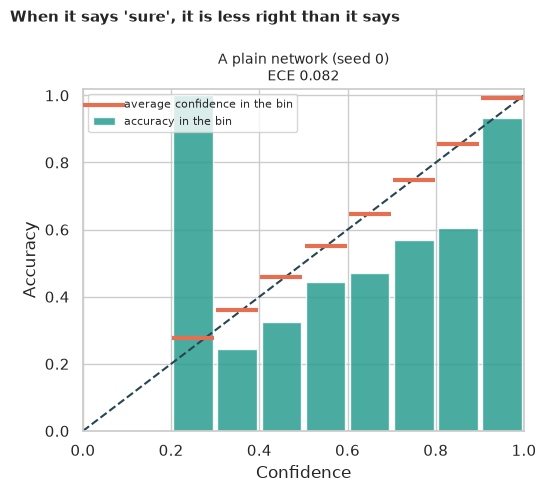

In [6]:
def reliability(probs: np.ndarray, labels: np.ndarray, bins: int = 10) -> pd.DataFrame:
    """Accuracy and average confidence in each confidence bin (for the reliability diagram)."""
    conf, correct = probs.max(1), probs.argmax(1) == labels
    edges = np.linspace(0, 1, bins + 1)
    index = np.clip(np.digitize(conf, edges[1:-1]), 0, bins - 1)
    rows = []
    for b in range(bins):
        pick = index == b
        rows.append(
            {
                "bin": b,
                "centre": (edges[b] + edges[b + 1]) / 2,
                "n": int(pick.sum()),
                "accuracy": correct[pick].mean() if pick.any() else np.nan,
                "confidence": conf[pick].mean() if pick.any() else np.nan,
            }
        )
    return pd.DataFrame(rows)


def draw_reliability(ax: plt.Axes, probs: np.ndarray, labels: np.ndarray, title: str) -> None:
    """A reliability diagram: bars are accuracy per confidence bin, the diagonal is honesty.

    An orange tick marks the average confidence in each bin: where it sits above the bar, the
    network claims more than it delivers.
    """
    table = reliability(probs, labels)
    table = table[table["n"] > 0]
    centre, accuracy = table["centre"].to_numpy(), table["accuracy"].to_numpy()
    confidence = table["confidence"].to_numpy()
    ax.bar(
        centre,
        accuracy,
        width=0.09,
        color=TEAL,
        alpha=0.85,
        edgecolor="white",
        label="accuracy in the bin",
    )
    ax.scatter(
        centre,
        confidence,
        marker="_",
        s=900,
        color=ORANGE,
        linewidths=3,
        label="average confidence in the bin",
        zorder=3,
    )
    ax.plot([0, 1], [0, 1], color=NAVY, ls="--", lw=1.5)
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("Confidence")
    ax.set_title(f"{title}\nECE {ece(probs, labels):.3f}", fontsize=10)


table0 = reliability(p0, test_labels)
table0["over-confidence"] = table0["confidence"] - table0["accuracy"]
print("Reliability table of network 0 (10 confidence bins):")
print(table0.drop(columns="bin").round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(5.5, 5))
draw_reliability(ax, p0, test_labels, "A plain network (seed 0)")
ax.set_ylabel("Accuracy")
ax.legend(loc="upper left", fontsize=8)
fig.suptitle(
    "When it says 'sure', it is less right than it says",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "01_reliability_plain.png", dpi=150)
plt.show()

**How to read this:**

- **The networks are over-confident in every seed:** accuracy **85.0% to 85.8%**, but average confidence **93.3% to 93.6%**: a gap of **8.1 points** on average (one-sample t-test p = 7e-7). The ECE is **0.076 to 0.086**; for network 0 it is **0.082** (95% CI 0.076 to 0.088). **We reject H₀.**
- **"Very sure" is not that sure:** the network is more than 99% confident on about **65%** of the test images, yet it is right on only **97.0% to 97.6%** of them: it says 99% and means 97%, and that is the *good* end of its range.
- **The reliability table and diagram (network 0)** show the pattern: in every confidence bin with a meaningful number of images (37 or more) the accuracy is **below** the confidence, by **0.11 to 0.25**. The worst is the bin of images it is about 85% sure of (**855 per thousand claimed, 606 delivered**: 609 images); and **81%** of all test images (8,097) fall in the top bin, where it claims **99.1%** and delivers **93.4%** (a gap of 0.057 that, because the bin is so full, makes up most of the ECE). (The tiny first bin, 2 images, is noise.)
- The over-confidence is a result of training to near-perfect accuracy on the training images: a network that has memorised its training set has learned to be sure.

## 8. H2: does temperature scaling fix it?

*What:* for each network we find one number T on the 5,000 **validation** images (a T above 1 softens the probabilities), divide the logits by it, and measure the ECE and NLL on the **test** set. We test with paired t-tests across the 5 networks, and count how many predictions change. *Why:* temperature scaling is the cheapest and most popular post-hoc fix: one parameter, no retraining.

In [7]:
temperatures = [fit_temperature(r["val"], val_y) for r in single]
rows = []
for s, (r, temp) in enumerate(zip(single, temperatures, strict=True)):
    before, after = softmax(r["test"]), softmax(r["test"], temp)
    rows.append(
        {
            "network": s,
            "T": temp,
            "accuracy before": (before.argmax(1) == test_labels).mean(),
            "accuracy after": (after.argmax(1) == test_labels).mean(),
            "ECE before": ece(before, test_labels),
            "ECE after": ece(after, test_labels),
            "NLL before": nll(before, test_labels),
            "NLL after": nll(after, test_labels),
            "average confidence after": after.max(1).mean(),
        }
    )
scaled = pd.DataFrame(rows).set_index("network")
print("Temperature scaling: T is fitted on the 5,000 validation images, the test set is untouched:")
print(scaled.round(3).to_string())
t_ece = stats.ttest_rel(scaled["ECE after"], scaled["ECE before"])
t_nll = stats.ttest_rel(scaled["NLL after"], scaled["NLL before"])
print(
    f"\nECE falls from {scaled['ECE before'].mean():.3f} to {scaled['ECE after'].mean():.3f} "
    f"(paired t-test p = {fmt_p(t_ece.pvalue)}); NLL from {scaled['NLL before'].mean():.3f} to "
    f"{scaled['NLL after'].mean():.3f} (p = {fmt_p(t_nll.pvalue)})"
)
changed = sum(
    int((softmax(r["test"]).argmax(1) != softmax(r["test"], t).argmax(1)).sum())
    for r, t in zip(single, temperatures, strict=True)
)
print(
    f"Predictions changed by temperature scaling over all 5 networks: {changed} of "
    f"{5 * len(test_labels):,} (it rescales every logit by the same number, so the order of the "
    "classes cannot change)"
)
p_ts = softmax(single[0]["test"], temperatures[0])
low = bootstrap(ece, p_ts, test_labels)
print(
    f"Network 0 after scaling: ECE {low[0]:.3f} (95% CI {low[1]:.3f} to {low[2]:.3f}) against "
    f"{ece_pt:.3f} before (CI {ece_lo:.3f} to {ece_hi:.3f})"
)

Temperature scaling: T is fitted on the 5,000 validation images, the test set is untouched:
             T  accuracy before  accuracy after  ECE before  ECE after  NLL before  NLL after  average confidence after
network                                                                                                                
0        2.006            0.854           0.854       0.082      0.008       0.570      0.430                     0.858
1        1.979            0.858           0.858       0.076      0.010       0.566      0.427                     0.860
2        2.048            0.850           0.850       0.086      0.011       0.600      0.445                     0.853
3        2.003            0.851           0.851       0.082      0.007       0.570      0.434                     0.854
4        2.052            0.854           0.854       0.081      0.012       0.566      0.430                     0.852

ECE falls from 0.082 to 0.010 (paired t-test p = 1.6e-06); NLL from

Network 0 after scaling: ECE 0.008 (95% CI 0.007 to 0.015) against 0.082 before (CI 0.076 to 0.088)


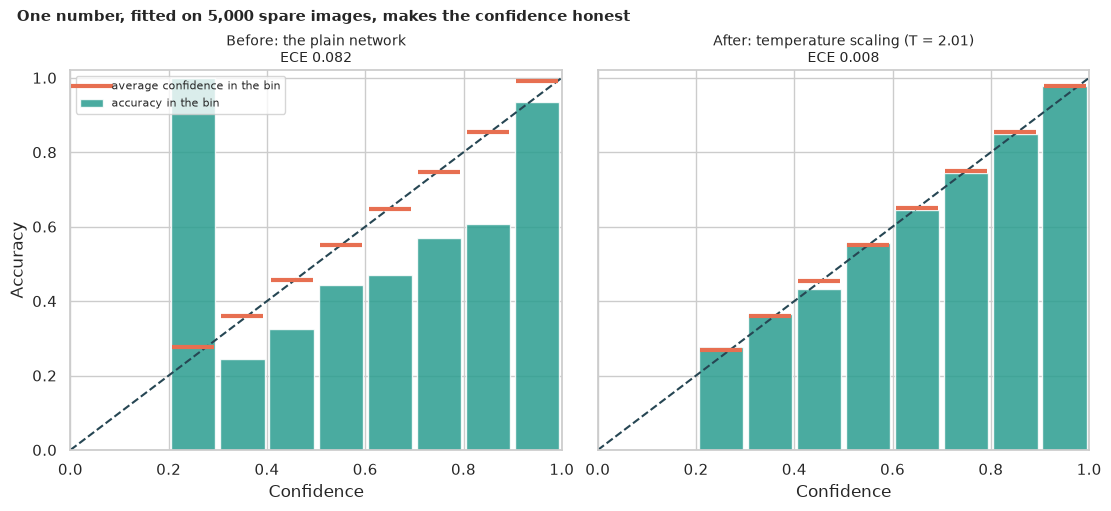

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True, layout="constrained")
draw_reliability(axes[0], p0, test_labels, "Before: the plain network")
draw_reliability(
    axes[1], p_ts, test_labels, f"After: temperature scaling (T = {temperatures[0]:.2f})"
)
axes[0].set_ylabel("Accuracy")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle(
    "One number, fitted on 5,000 spare images, makes the confidence honest",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.savefig(OUT_DIR / "02_temperature_scaling.png", dpi=150)
plt.show()

**How to read this:**

- **The fitted temperatures are consistent:** **T = 2.01, 1.98, 2.05, 2.00 and 2.05**: the networks were about twice as sure as they should be (in logit scale).
- **Calibration is repaired:** the ECE falls from **0.082 to 0.010** on average (network 0: **0.008**, 95% CI 0.007 to 0.015), a paired t-test across the 5 networks gives p = 2e-6, and the NLL falls from **0.575 to 0.433** (p = 2e-6). The average confidence after scaling (0.852 to 0.860) is now equal to the accuracy (0.850 to 0.858). **We reject H₀.**
- **Not one prediction changes:** **0 of 50,000.** Dividing every logit by the same number cannot change which class has the highest score, so the accuracy is untouched. Temperature scaling changes *how loudly* the model speaks, not *what* it says.

## 9. H3: what do the other remedies do?

*What:* the same test-set measurements for all remedies: temperature scaling; **training with augmentation**; **label smoothing**; augmentation combined with scaling; the **deep ensemble** (the 5 plain networks, with their probabilities averaged, a kind of panel of forecasters); and an ensemble of 5 networks that were each temperature-scaled first. We also test the ensemble against a single network (exact McNemar test) and bootstrap its ECE and NLL against temperature scaling alone. *Why:* temperature scaling is not the only cure, and the cures can interact.

In [9]:
def members(kind: str, calibrate: bool = False) -> list[np.ndarray]:
    """Probabilities of every network of a kind on the test set (optionally temperature-scaled)."""
    out = []
    for r in runs[kind]:
        temp = fit_temperature(r["val"], val_y) if calibrate else 1.0
        out.append(softmax(r["test"], temp))
    return out


plain_probs = members("plain")
ensemble = np.mean(plain_probs, axis=0)
ensemble_ts = np.mean(members("plain", calibrate=True), axis=0)
rows = []
methods = {
    "plain network (average of 5)": [softmax(r["test"]) for r in runs["plain"]],
    "temperature scaling (average of 5)": members("plain", calibrate=True),
    "trained with augmentation (average of 3)": members("augmented"),
    "trained with label smoothing (average of 3)": members("label smoothing"),
    "augmentation + temperature scaling (average of 3)": members("augmented", calibrate=True),
}
for name, group in methods.items():
    rows.append(
        {
            "method": name,
            "accuracy": np.mean([(p.argmax(1) == test_labels).mean() for p in group]),
            "ECE": np.mean([ece(p, test_labels) for p in group]),
            "NLL": np.mean([nll(p, test_labels) for p in group]),
            "Brier": np.mean([brier(p, test_labels) for p in group]),
        }
    )
for name, p in [
    ("ensemble of 5 plain networks", ensemble),
    ("ensemble of 5 temperature-scaled networks", ensemble_ts),
]:
    rows.append(
        {
            "method": name,
            "accuracy": (p.argmax(1) == test_labels).mean(),
            "ECE": ece(p, test_labels),
            "NLL": nll(p, test_labels),
            "Brier": brier(p, test_labels),
        }
    )
fixes = pd.DataFrame(rows).set_index("method")
print(fixes.round(4).to_string())
single_correct = plain_probs[0].argmax(1) == test_labels
ens_correct = ensemble.argmax(1) == test_labels
mc = mcnemar(
    [
        [int((single_correct & ens_correct).sum()), int((single_correct & ~ens_correct).sum())],
        [int((~single_correct & ens_correct).sum()), int((~single_correct & ~ens_correct).sum())],
    ],
    exact=True,
)
only_ens = int((~single_correct & ens_correct).sum())
only_single = int((single_correct & ~ens_correct).sum())
print(
    f"\nEnsemble vs network 0: right only for the ensemble {only_ens}, only for the network "
    f"{only_single} (exact McNemar p = {fmt_p(mc.pvalue)})"
)
for label, p in [
    ("ensemble", ensemble),
    ("temperature scaling alone", softmax(single[0]["test"], temperatures[0])),
]:
    e = bootstrap(ece, p, test_labels)
    n = bootstrap(nll, p, test_labels)
    print(
        f"{label} (network 0 for the second): ECE {e[0]:.4f} (CI {e[1]:.4f} to {e[2]:.4f}), "
        f"NLL {n[0]:.3f} (CI {n[1]:.3f} to {n[2]:.3f})"
    )

                                                   accuracy     ECE     NLL   Brier
method                                                                             
plain network (average of 5)                         0.8533  0.0816  0.5746  0.2302
temperature scaling (average of 5)                   0.8533  0.0095  0.4331  0.2103
trained with augmentation (average of 3)             0.8847  0.0208  0.3427  0.1678
trained with label smoothing (average of 3)          0.8541  0.1068  0.5296  0.2305
augmentation + temperature scaling (average of 3)    0.8847  0.0067  0.3363  0.1666
ensemble of 5 plain networks                         0.8882  0.0157  0.3540  0.1656
ensemble of 5 temperature-scaled networks            0.8902  0.0629  0.3573  0.1708

Ensemble vs network 0: right only for the ensemble 540, only for the network 202 (exact McNemar p = 2.1e-36)


ensemble (network 0 for the second): ECE 0.0157 (CI 0.0127 to 0.0220), NLL 0.354 (CI 0.336 to 0.373)


temperature scaling alone (network 0 for the second): ECE 0.0083 (CI 0.0066 to 0.0155), NLL 0.430 (CI 0.413 to 0.448)


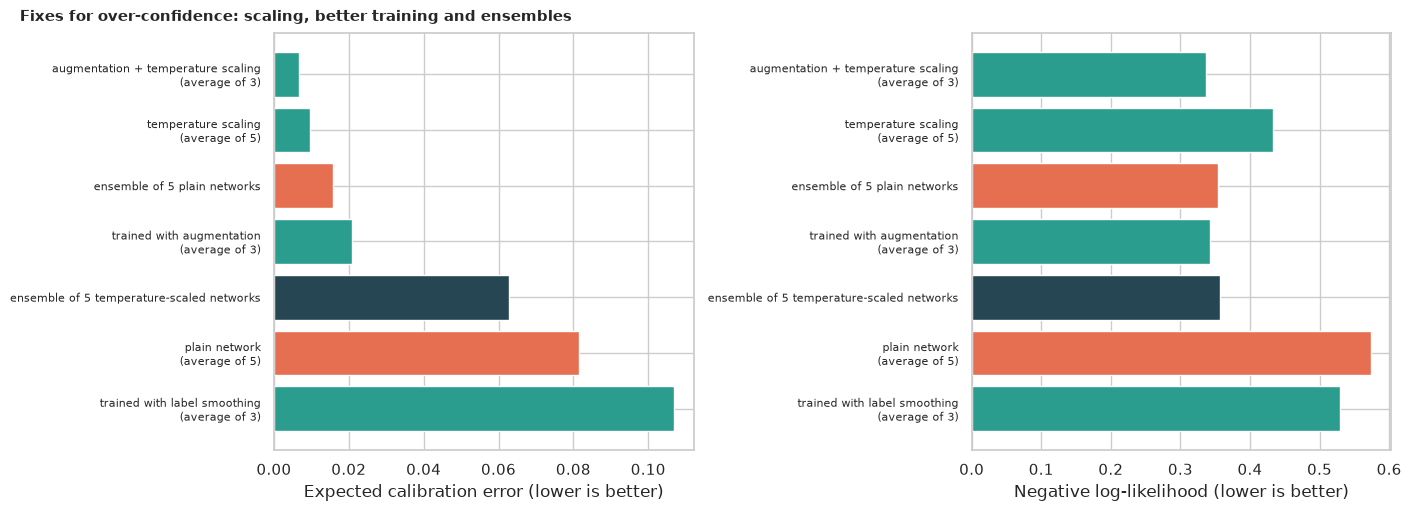

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout="constrained")
order = fixes.sort_values("ECE", ascending=False).index
colors = [ORANGE if "plain network" in n else NAVY if "ensemble" in n else TEAL for n in order]
for ax, column, label in zip(
    axes,
    ["ECE", "NLL"],
    ["Expected calibration error (lower is better)", "Negative log-likelihood (lower is better)"],
    strict=True,
):
    ax.barh(range(len(order)), fixes.loc[order, column], color=colors)
    ax.set_yticks(
        range(len(order)), [n.replace(" (average", "\n(average") for n in order], fontsize=8
    )
    ax.set_xlabel(label)
fig.suptitle(
    "Fixes for over-confidence: scaling, better training and ensembles",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.savefig(OUT_DIR / "03_fixes.png", dpi=150)
plt.show()

**How to read this:**

| Method | Accuracy | ECE | NLL | Brier |
|---|---|---|---|---|
| Plain network (average of 5) | 85.3% | 0.082 | 0.575 | 0.230 |
| Temperature scaling | 85.3% | **0.010** | 0.433 | 0.210 |
| Trained with augmentation | 88.5% | 0.021 | 0.343 | 0.168 |
| Trained with label smoothing | 85.4% | 0.107 | 0.530 | 0.231 |
| Augmentation + temperature scaling | 88.5% | **0.007** | **0.336** | 0.167 |
| Ensemble of 5 plain networks | 88.8% | 0.016 | 0.354 | **0.166** |
| Ensemble of 5 temperature-scaled networks | **89.0%** | 0.063 | 0.357 | 0.171 |

- **Temperature scaling gives the best calibration for a single network** (ECE 0.010 from 0.082) but does not improve the accuracy.
- **Label smoothing made it worse here:** ECE **0.107** against 0.082. It does lower the confidence, but too much (the network becomes *under*-confident), which shows that "a regulariser that discourages certainty" is not a calibration method.
- **Augmentation helps both accuracy and calibration** (88.5% and ECE 0.021) because the network no longer memorises the training set; adding temperature scaling brings the ECE to **0.007**, the best of all.
- **The ensemble is the strongest in accuracy and in the scoring rules:** 88.8% against 85.4% for a single network (it is right alone on **540** images where the single network is wrong alone on **202**; exact McNemar p = 2e-36), with ECE **0.016** (95% CI 0.013 to 0.022), a lower NLL (**0.354** against **0.430** for temperature scaling alone, whose intervals do not overlap) and the best Brier score. For calibration alone, temperature scaling of one network (ECE 0.008) is slightly better than the ensemble (0.016), within the noise of the intervals.
- **A trap:** scaling each ensemble member first and then averaging gives an ECE of **0.063**: each member was softened, and averaging softens them again, so the ensemble becomes under-confident. Combine remedies by checking the result, not by stacking.

## 10. H4: does uncertainty find mistakes and strangers?

*What:* calibration matters because the confidence is used to decide. Three uses. **(a) Finding mistakes:** the AUROC with which the confidence separates right from wrong answers (1 is perfect, 0.5 is a coin flip), for the single network, the ensemble's confidence, and the ensemble's disagreement (the **mutual information**: how much the members' predictions differ, a measure of *epistemic* uncertainty). **(b) Selective prediction:** the accuracy if the model answers only the images it is most confident about (100%, 90%, 80% and 50% of the images). **(c) Spotting strangers:** the AUROC of confidence for telling CIFAR-10 test images from CIFAR-100 and SVHN images (with bootstrap intervals). *Why:* a "can this be trusted?" signal is the point of uncertainty.

In [11]:
def max_prob(p: np.ndarray) -> np.ndarray:
    """Confidence: the largest class probability."""
    return p.max(1)


def mutual_information(member_probs: list[np.ndarray]) -> np.ndarray:
    """Epistemic uncertainty of an ensemble: how much its members disagree.

    The entropy of the average prediction minus the average entropy of the members' predictions.

    Args:
        member_probs: Class probabilities of every member, each shape (N, classes).

    Returns:
        One number per image (0 when all members agree exactly).
    """
    mean = np.mean(member_probs, axis=0)
    total = -(mean * np.log(np.clip(mean, 1e-12, None))).sum(1)
    each = np.mean([-(p * np.log(np.clip(p, 1e-12, None))).sum(1) for p in member_probs], axis=0)
    return total - each


correct = ensemble.argmax(1) == test_labels
single_p = plain_probs[0]
single_correct = single_p.argmax(1) == test_labels
mi_test = mutual_information(plain_probs)
rows = [
    {
        "score": "single network, confidence",
        "AUROC (right vs wrong)": roc_auc_score(single_correct, max_prob(single_p)),
    },
    {
        "score": "ensemble, confidence",
        "AUROC (right vs wrong)": roc_auc_score(correct, max_prob(ensemble)),
    },
    {
        "score": "ensemble, low disagreement",
        "AUROC (right vs wrong)": roc_auc_score(correct, -mi_test),
    },
]
print(pd.DataFrame(rows).set_index("score").round(3).to_string())
print("\nAccuracy if the model answers only the images it is most confident about:")
coverage_rows = []
for name, p, ok in [("single network", single_p, single_correct), ("ensemble", ensemble, correct)]:
    order = np.argsort(-max_prob(p))
    for cov in (1.0, 0.9, 0.8, 0.5):
        keep = order[: int(cov * len(order))]
        coverage_rows.append({"model": name, "coverage": cov, "accuracy": ok[keep].mean()})
print(
    pd.DataFrame(coverage_rows)
    .pivot(index="coverage", columns="model", values="accuracy")
    .sort_index(ascending=False)
    .round(4)
    .to_string()
)
ood_rows = []
for name in ("CIFAR-100", "SVHN"):
    single_ood = softmax(single[0][name])
    members_ood = [softmax(r[name]) for r in single]
    mean_ood = np.mean(members_ood, axis=0)
    labels = np.r_[np.ones(len(test_labels)), np.zeros(len(single_ood))]
    for score_name, id_score, ood_score in [
        ("single network, confidence", max_prob(single_p), max_prob(single_ood)),
        ("ensemble, confidence", max_prob(ensemble), max_prob(mean_ood)),
        ("ensemble, low disagreement", -mi_test, -mutual_information(members_ood)),
    ]:
        scores = np.r_[id_score, ood_score]
        boots = []
        for _ in range(200):
            pick = rng.integers(0, len(scores), len(scores))
            boots.append(roc_auc_score(labels[pick], scores[pick]))
        ood_rows.append(
            {
                "unfamiliar images": name,
                "score": score_name,
                "AUROC": roc_auc_score(labels, scores),
                "low": np.percentile(boots, 2.5),
                "high": np.percentile(boots, 97.5),
            }
        )
ood = pd.DataFrame(ood_rows)
print("\nTelling CIFAR-10 test images from images of other things (1 = perfect, 0.5 = guessing):")
print(ood.round(3).to_string(index=False))
print(
    f"\nAverage confidence of network 0: CIFAR-10 test {max_prob(single_p).mean():.3f}, "
    f"CIFAR-100 {max_prob(softmax(single[0]['CIFAR-100'])).mean():.3f}, SVHN "
    f"{max_prob(softmax(single[0]['SVHN'])).mean():.3f}"
)

                            AUROC (right vs wrong)
score                                             
single network, confidence                   0.879
ensemble, confidence                         0.895
ensemble, low disagreement                   0.873

Accuracy if the model answers only the images it is most confident about:
model     ensemble  single network
coverage                          
1.0         0.8882          0.8544
0.9         0.9337          0.9001
0.8         0.9620          0.9372
0.5         0.9944          0.9888



Telling CIFAR-10 test images from images of other things (1 = perfect, 0.5 = guessing):
unfamiliar images                      score  AUROC   low  high
        CIFAR-100 single network, confidence  0.792 0.786 0.797
        CIFAR-100       ensemble, confidence  0.825 0.821 0.831
        CIFAR-100 ensemble, low disagreement  0.814 0.810 0.821
             SVHN single network, confidence  0.838 0.832 0.844
             SVHN       ensemble, confidence  0.844 0.838 0.849
             SVHN ensemble, low disagreement  0.789 0.783 0.796

Average confidence of network 0: CIFAR-10 test 0.936, CIFAR-100 0.806, SVHN 0.767


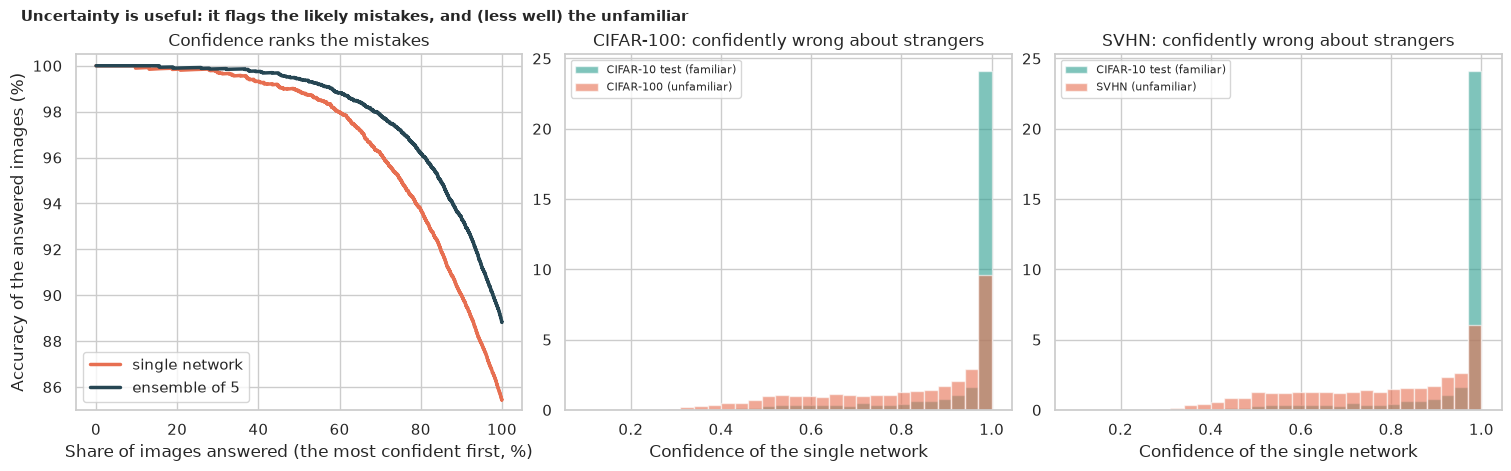

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), layout="constrained")
for name, p, ok, color in [
    ("single network", single_p, single_correct, ORANGE),
    ("ensemble of 5", ensemble, correct, NAVY),
]:
    order = np.argsort(-max_prob(p))
    cum = np.cumsum(ok[order]) / np.arange(1, len(order) + 1)
    axes[0].plot(
        np.arange(1, len(order) + 1) / len(order) * 100, cum * 100, color=color, lw=2.5, label=name
    )
axes[0].set_xlabel("Share of images answered (the most confident first, %)")
axes[0].set_ylabel("Accuracy of the answered images (%)")
axes[0].set_ylim(85, 100.5)
axes[0].set_title("Confidence ranks the mistakes")
axes[0].legend()
bins = np.linspace(0.1, 1, 31)
for ax, name in zip(axes[1:], ("CIFAR-100", "SVHN"), strict=True):
    ax.hist(
        max_prob(single_p),
        bins=bins,
        alpha=0.6,
        color=TEAL,
        density=True,
        label="CIFAR-10 test (familiar)",
    )
    ax.hist(
        max_prob(softmax(single[0][name])),
        bins=bins,
        alpha=0.6,
        color=ORANGE,
        density=True,
        label=f"{name} (unfamiliar)",
    )
    ax.set_xlabel("Confidence of the single network")
    ax.set_title(f"{name}: confidently wrong about strangers")
    ax.legend(fontsize=8)
fig.suptitle(
    "Uncertainty is useful: it flags the likely mistakes, and (less well) the unfamiliar",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.savefig(OUT_DIR / "04_uncertainty.png", dpi=150)
plt.show()

**How to read this:**

- **Confidence ranks the mistakes well:** the AUROC for right-versus-wrong is **0.879** for a single network, **0.895** for the ensemble's confidence and 0.873 for its disagreement. Wrong answers do tend to be the less confident ones.
- **Answering only what you are sure about pays:** with the ensemble, answering the most confident **90%** of the images gives **93.4%** accuracy (against 88.8% on everything), the top **80%** gives **96.2%** and the top **50%** gives **99.4%**; the single network gets 90.0%, 93.7% and 98.9% at the same coverages. This is how a system decides to pass doubtful cases to a human.
- **Strangers are harder to spot:** distinguishing CIFAR-10 from CIFAR-100 images by confidence has an AUROC of only **0.792** for the single network (CI 0.786 to 0.797) and **0.825** for the ensemble (CI 0.821 to 0.831); for SVHN **0.838** and **0.844**. The ensemble's disagreement helps for CIFAR-100 (0.814) but is worse for SVHN (0.789).
- **The network is confidently wrong about strangers:** its average confidence is **0.936** on CIFAR-10 test images, but still **0.806** on CIFAR-100 and **0.767** on SVHN images, for which every answer is wrong by definition. **We reject H₀** (all the AUROCs are far above 0.5) but note the limit: **a confidence score is a weak detector of unfamiliar images.**

## 11. H5: does calibration survive a change in the data?

*What:* Gaussian noise of standard deviation 0, 0.05, 0.1, 0.15, 0.2 and 0.3 is added to the test images. At each level we measure the accuracy, the average confidence and the ECE of the plain networks, the networks temperature-scaled **with the T fitted on the clean validation images**, and the ensemble. *Why:* in production the data are never quite the data of the validation set; a calibration that holds only on tidy images is a trap.

In [13]:
rows = []
for level in NOISE_LEVELS:
    key = "test" if level == 0 else f"noise {level}"
    for method in (
        "plain network",
        "temperature-scaled (T from clean validation)",
        "ensemble of 5",
    ):
        if method == "ensemble of 5":
            groups = [np.mean([softmax(r[key]) for r in single], axis=0)]
        elif method.startswith("temperature"):
            groups = [softmax(r[key], t) for r, t in zip(single, temperatures, strict=True)]
        else:
            groups = [softmax(r[key]) for r in single]
        rows.append(
            {
                "noise": level,
                "method": method,
                "accuracy": np.mean([(p.argmax(1) == test_labels).mean() for p in groups]),
                "ECE": np.mean([ece(p, test_labels) for p in groups]),
                "average confidence": np.mean([p.max(1).mean() for p in groups]),
            }
        )
shift = pd.DataFrame(rows)
wide = shift.pivot(
    index="noise", columns="method", values=["accuracy", "ECE", "average confidence"]
)
print(wide.round(3).to_string())
for method in shift["method"].unique():
    sub = shift[shift["method"] == method]
    rho = stats.spearmanr(sub["noise"], sub["ECE"])
    print(
        f"{method}: ECE rises with the noise level in {int((sub['ECE'].diff().dropna() > 0).sum())}"
        f" of {len(sub) - 1} steps (Spearman {rho.statistic:+.2f} over {len(sub)} levels)"
    )

            accuracy                                                                      ECE                                                            average confidence                                                           
method ensemble of 5 plain network temperature-scaled (T from clean validation) ensemble of 5 plain network temperature-scaled (T from clean validation)      ensemble of 5 plain network temperature-scaled (T from clean validation)
noise                                                                                                                                                                                                                                 
0.00           0.888         0.853                                        0.853         0.016         0.082                                        0.010              0.887         0.935                                        0.855
0.05           0.676         0.633                                        0.

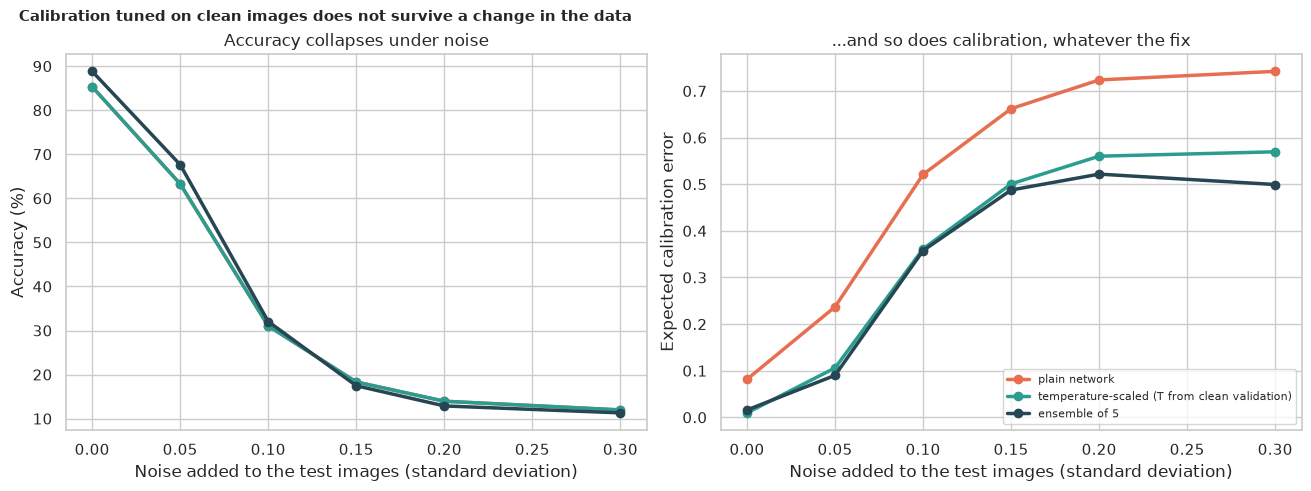

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8), layout="constrained")
for method, color in [
    ("plain network", ORANGE),
    ("temperature-scaled (T from clean validation)", TEAL),
    ("ensemble of 5", NAVY),
]:
    sub = shift[shift["method"] == method]
    axes[0].plot(sub["noise"], sub["accuracy"] * 100, color=color, marker="o", lw=2.5, label=method)
    axes[1].plot(sub["noise"], sub["ECE"], color=color, marker="o", lw=2.5, label=method)
axes[0].set_xlabel("Noise added to the test images (standard deviation)")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_title("Accuracy collapses under noise")
axes[1].set_xlabel("Noise added to the test images (standard deviation)")
axes[1].set_ylabel("Expected calibration error")
axes[1].set_title("...and so does calibration, whatever the fix")
axes[1].legend(fontsize=8)
fig.suptitle(
    "Calibration tuned on clean images does not survive a change in the data",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.savefig(OUT_DIR / "05_shift.png", dpi=150)
plt.show()

**How to read this:**

| Noise (sd) | Accuracy (plain) | ECE plain | ECE scaled (T from clean data) | ECE ensemble |
|---|---|---|---|---|
| 0 (clean) | 85.3% | 0.082 | **0.010** | 0.016 |
| 0.05 | 63.3% | 0.237 | 0.106 | **0.090** |
| 0.10 | 31.0% | 0.521 | 0.361 | **0.358** |
| 0.15 | 18.3% | 0.662 | 0.501 | **0.488** |
| 0.20 | 13.9% | 0.724 | 0.560 | **0.522** |
| 0.30 | 12.0% | 0.742 | 0.570 | **0.499** |

- **A little noise destroys the network:** accuracy falls from 85.3% to 63.3% at a standard deviation of 0.05 and to chance (about 12%) at 0.3: this network was trained without augmentation and has never seen noise.
- **Its confidence does not fall with it:** the average confidence stays at **83% to 87%** at every noise level, even when the accuracy is 12%: at noise 0.2 it is 86% sure and right 14% of the time. The ECE rises with every step of noise, from **0.082 to 0.742**.
- **Temperature scaling does not survive the shift:** the temperature fitted on clean images keeps its edge (ECE 0.561 against 0.724 at noise 0.2) but the calibration is gone (ECE 0.106 at the smallest noise already ten times its clean value, and 0.57 at the largest). The ensemble is the best of the three at every noisy level (ECE 0.090 against 0.106 at 0.05, and 0.499 against 0.570 at 0.3), but all three are miscalibrated.
- **The lesson:** calibration is a property of a model *on a given distribution of data*. Fixing it on a validation set protects you only as long as production looks like the validation set: monitor it, and train with the corruptions you expect (augmentation).

## 12. 🎯 Takeaways

1. **A CIFAR-10 network is over-confident:** 93.5% average confidence for 85.3% accuracy (a gap of 8.1 points, ECE 0.082); "99% sure" is right 97% of the time.
2. **One number fixes it on clean data:** temperature scaling (T of about 2, fitted on 5,000 spare images) cuts the ECE from 0.082 to 0.010 and the NLL from 0.575 to 0.433, and changes **no** prediction.
3. **Remedies are not equal:** label smoothing made calibration worse (ECE 0.107); augmentation improved accuracy and ECE together (88.5%, 0.021); an ensemble of five gave the best accuracy (88.8%) and scores (NLL 0.354), and augmentation plus temperature scaling gave the best ECE (0.007).
4. **Do not stack remedies blindly:** temperature-scaling each ensemble member made the ensemble under-confident (ECE 0.063).
5. **Confidence is useful for triage:** answering only the most confident 80% of images lifts the ensemble's accuracy from 88.8% to 96.2%.
6. **But it is a weak alarm for unfamiliar images:** AUROC 0.79 to 0.84; the network is still 77% to 81% confident on images of other things.
7. **Calibration does not travel:** under noise the accuracy collapses while the confidence stays near 85%, and every fix loses most of its value.

## 13. ⚠️ Limitations

- **One dataset, one small network, one recipe.** Larger, more regularised or pretrained networks are often better calibrated (or differently miscalibrated); label smoothing and augmentation settings were not tuned.
- **Eleven networks.** The 5-network tests have low power (the smallest possible p-value of a paired test with 5 pairs is 0.06 for a rank test), so we used paired t-tests, which assume roughly normal differences.
- **ECE depends on the binning** (15 equal-width bins here) and has a small-sample bias; it was bootstrapped, but other binnings would give somewhat different values. The NLL and Brier score do not have this problem.
- **Temperature scaling used 5,000 validation images,** and fitting more flexible calibrators (vector scaling, isotonic regression) was not tried.
- **Noise is only one kind of shift;** blur, weather and changes of camera behave differently, and the networks here were trained without any augmentation against noise.
- **Ensembles cost five times as much** to train and to run, which is not counted here.
- **Out-of-distribution detection used simple scores** (the largest probability, the mutual information); methods built for the purpose (feature-distance scores, trained detectors) do better.
- **The fixes are post-hoc and on average:** a model that is calibrated on average can still be badly calibrated for a class or a subgroup, which we did not examine.